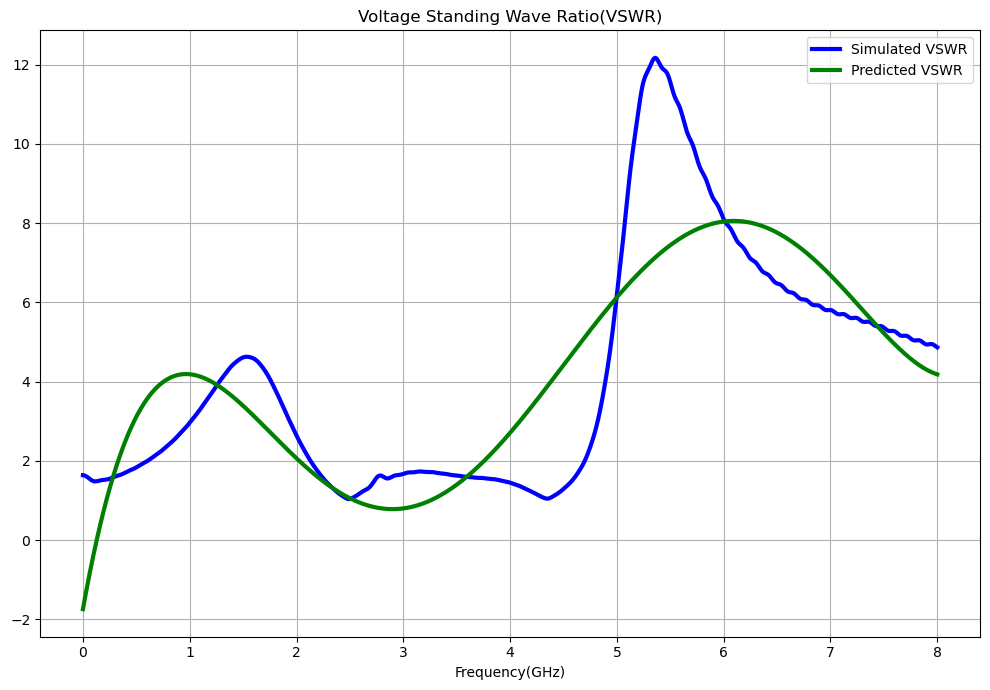

In [17]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# Load CSV file
# Replace path if needed
df = pd.read_csv("vswr.csv")

# Keep only required columns and drop NaN
df = df[['Frequency_in_GHz', 'VSWR1']].dropna()

# Features (X) and target (y)
X = df[['Frequency_in_GHz']].values
y = df['VSWR1'].values

# Polynomial Regression (ML model)
plg = PolynomialFeatures(degree=5)
X_plg = plg.fit_transform(X)

model = LinearRegression()
model.fit(X_plg, y)

# Sort values for smooth plotting
sort_idx = np.argsort(X.flatten())
x_sorted = X[sort_idx]
y_sorted = y[sort_idx]

# Predict using ML model
y_pred = model.predict(plg.transform(x_sorted))

# Plot results
plt.figure(figsize=(10, 7))

# Plot the actual data points
plt.plot(X, y, color='blue',linewidth=3, label='Simulated VSWR')

# Plot the Machine Learning Prediction
plt.plot(X, y_pred, color='green',linewidth=3 ,label=f'Predicted VSWR')

plt.xlabel("Frequency(GHz)")
plt.title("Voltage Standing Wave Ratio(VSWR)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('vswr.png')
plt.show()